# 03 — Exploratory Data Analysis, Statistical Analysis & Time-Series Analysis
**Pipeline stage:** `Data Cleaning → EDA → Statistical Analysis → Time-Series Analysis → ...`

This notebook analyzes `data/processed/ILA_cleaned.csv` (output of Notebook 02). All
figures include titles, axis labels and a grid; every figure is followed by a printed,
data-driven interpretation — no figure is left to speak for itself.

**Important data-granularity caveat, stated upfront:** the only time information available
is a yearly campaign (`annee`, 2020-2025) plus a within-campaign point order
(`chrono_rank_in_instrument` from Notebook 02). This is coarser than a true timestamp.
Time-series techniques below (ACF, stationarity tests, change-point detection) are applied
honestly given this constraint, and the notebook explicitly flags where the series is too
short for a technique to be statistically meaningful, rather than overstating conclusions.


## 1. Imports

In [1]:

import sys, logging
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import ruptures as rpt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")
plt.rcParams["figure.facecolor"] = "white"

print("Imports OK -", datetime.now().isoformat(timespec="seconds"))


Imports OK - 2026-08-22T12:51:57


## 2. Configuration

In [2]:

project_root = next(c for c in [Path.cwd(), Path.cwd().parent] if (c / "config" / "config.yaml").exists())
sys.path.insert(0, str(project_root))

from src.utils.config import load_config
from src.utils.data_discovery import discover_dataset

cfg = load_config()
DATA_PROCESSED = project_root / cfg["paths"]["data_processed"]
REPORTS_FIGURES = project_root / cfg["paths"]["reports_figures"] / "03_eda_stats_timeseries"
REPORTS_QUALITY = project_root / cfg["paths"]["reports_quality"]
LOGS_DIR = project_root / cfg["paths"]["logs"]
for d in [REPORTS_FIGURES, LOGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[logging.FileHandler(LOGS_DIR / "03_eda_stats_timeseries.log", mode="w"), logging.StreamHandler(sys.stdout)],
)
logger = logging.getLogger("03_eda")
ALPHA = 0.05  # significance level used throughout this notebook


## 3. Load Dataset

In [3]:

DATASET_PATH, _ = discover_dataset(
    search_dirs=[DATA_PROCESSED],
    expected_columns=cfg["expected_columns"],
    exclude_keywords=cfg["dataset_discovery"]["exclude_keywords"],
    split_keywords=cfg["dataset_discovery"]["split_keywords"],
    prefer_split=False,
    logger=logger,
)
print(f">>> Dataset selected: {DATASET_PATH.relative_to(project_root)}")
df = pd.read_csv(DATASET_PATH)
print(f"Shape: {df.shape}")
display(df.head())


2026-08-22 12:51:57,974 | INFO | Found 6 candidate CSV file(s) in [PosixPath('/home/claude/project2/metrology-ai-pipeline/data/processed')]


2026-08-22 12:51:58,011 | INFO | Selected dataset (prefer_split=False, full schema match): ILA_cleaned.csv


2026-08-22 12:51:58,012 | INFO | DATASET SELECTED: /home/claude/project2/metrology-ai-pipeline/data/processed/ILA_cleaned.csv (763 rows, 12/12 expected columns matched)


>>> Dataset selected: data/processed/ILA_cleaned.csv
Shape: (763, 23)


,id_instrument,lab,annee,point,consigne,valeur_reference,incertitude,EMT_basse,EMT_haute,min,max,conforme,lab_original,lab_clean,point_numeric,point_label,point_type,consigne_missing,emt_missing,conforme_recomputed,outlier_iqr_valeur_reference,outlier_zscore_per_instrument,chrono_rank_in_instrument
0,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2020,1,NaN,24.10,0.07,24.0,26.0,24.03,24.17,conforme,lab 03B,lab03b,1.0,NaN,numeric,True,False,False,False,False,0
1,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2020,2,NaN,24.00,0.07,24.0,26.0,23.93,24.07,non conforme,lab 03B,lab03b,2.0,NaN,numeric,True,False,False,False,False,1
2,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2021,1,NaN,24.08,0.20,24.0,26.0,23.88,24.28,non conforme,lab 03B,lab03b,1.0,NaN,numeric,True,False,False,False,False,2
3,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2021,2,NaN,23.81,0.20,24.0,26.0,23.61,24.01,non conforme,lab 03B,lab03b,2.0,NaN,numeric,True,False,False,False,False,3
4,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2022,1,NaN,24.08,0.20,24.0,26.0,23.88,24.28,non conforme,lab 03B,lab03b,1.0,NaN,numeric,True,False,False,False,False,4


### 3.1 Derived metrology quantities used throughout this notebook

- `erreur` = `consigne - valeur_reference` - the instrument's indication error (nominal
  reading minus the traceable reference value), when both are available.
- `marge_EMT` = `min(min - EMT_basse, EMT_haute - max)` - the same margin-to-tolerance
  metric already used in the upstream extraction pipeline (`src/data/extract_organize_ila.py`),
  recomputed here for consistency.


In [4]:

df["erreur"] = df["consigne"] - df["valeur_reference"]
df["marge_EMT"] = df.apply(
    lambda r: min(r["min"] - r["EMT_basse"], r["EMT_haute"] - r["max"])
    if pd.notna(r["min"]) and pd.notna(r["max"]) and pd.notna(r["EMT_basse"]) and pd.notna(r["EMT_haute"])
    else np.nan, axis=1
)
print(f"'erreur' available for {df['erreur'].notna().sum()} / {len(df)} rows.")
print(f"'marge_EMT' available for {df['marge_EMT'].notna().sum()} / {len(df)} rows.")


'erreur' available for 500 / 763 rows.
'marge_EMT' available for 734 / 763 rows.


## 4. Exploratory Data Analysis

### 4.1 Histograms & density plots

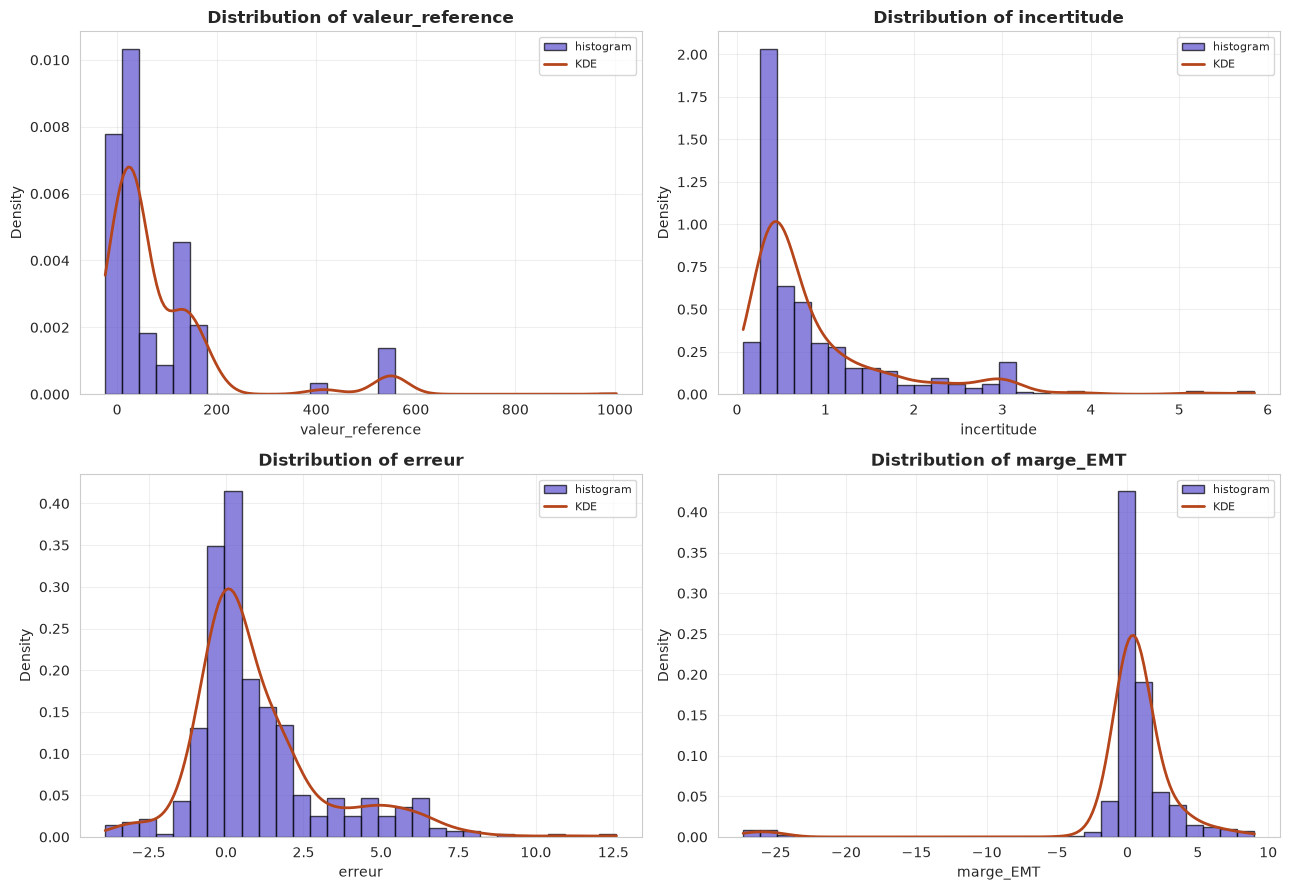

valeur_reference: mean=82.1814, median=37.3500, std=128.9710, skew=2.872, kurtosis=9.223
incertitude: mean=0.9002, median=0.5100, std=0.8628, skew=2.358, kurtosis=6.810
erreur: mean=1.0491, median=0.4000, std=2.1859, skew=1.452, kurtosis=3.077
marge_EMT: mean=0.2241, median=0.4300, std=4.4778, skew=-4.768, kurtosis=26.276


In [5]:

numeric_cols = ["valeur_reference", "incertitude", "erreur", "marge_EMT"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), numeric_cols):
    data = df[col].dropna()
    ax.hist(data, bins=30, density=True, color="#5C4FCF", edgecolor="black", alpha=0.7, label="histogram")
    if len(data) > 1 and data.std() > 0:
        kde = stats.gaussian_kde(data)
        xs = np.linspace(data.min(), data.max(), 200)
        ax.plot(xs, kde(xs), color="#B5451B", linewidth=2, label="KDE")
    ax.set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    ax.set_xlabel(col); ax.set_ylabel("Density"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "01_histograms_density.png", dpi=150)
plt.show()

for col in numeric_cols:
    data = df[col].dropna()
    print(f"{col}: mean={data.mean():.4f}, median={data.median():.4f}, std={data.std():.4f}, "
          f"skew={stats.skew(data):.3f}, kurtosis={stats.kurtosis(data):.3f}")


### 4.2 Boxplots & violin plots by conformity

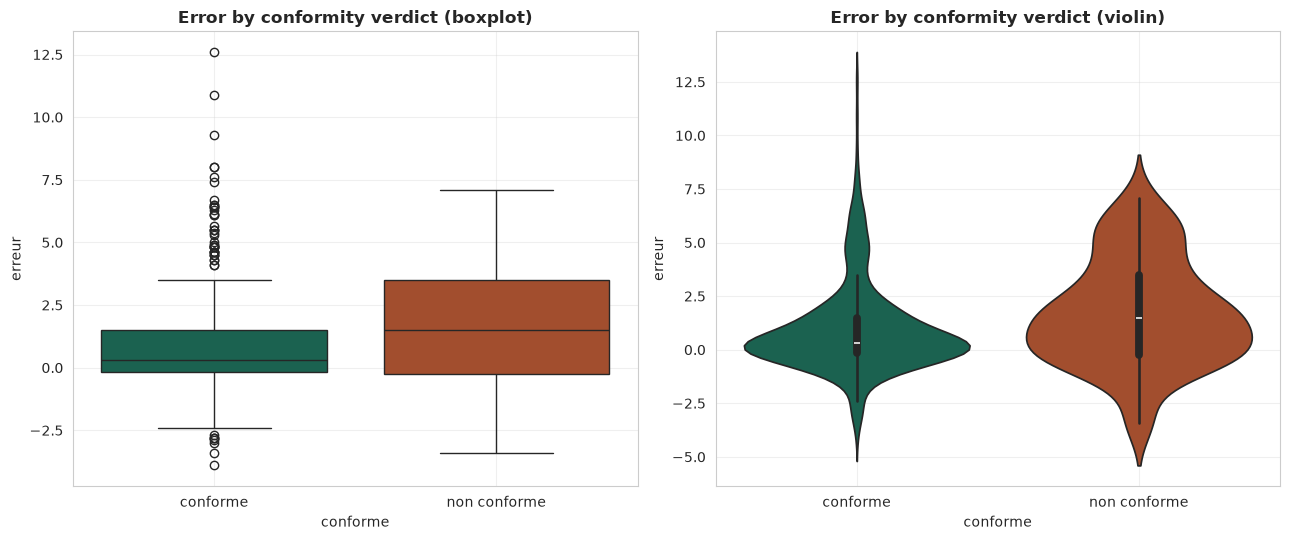

                  mean       std  count
conforme                               
conforme      0.962539  2.125130    382
non conforme  1.696211  2.484886     95

Interpretation: mean |erreur| is higher for 'non conforme' measurements in this sample.


In [6]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_df = df.dropna(subset=["conforme", "erreur"])
sns.boxplot(data=plot_df, x="conforme", y="erreur", ax=axes[0], hue="conforme",
            palette=["#0F6E56", "#B5451B"], legend=False)
axes[0].set_title("Error by conformity verdict (boxplot)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("conforme"); axes[0].set_ylabel("erreur"); axes[0].grid(alpha=0.3)

sns.violinplot(data=plot_df, x="conforme", y="erreur", ax=axes[1], hue="conforme",
               palette=["#0F6E56", "#B5451B"], legend=False)
axes[1].set_title("Error by conformity verdict (violin)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("conforme"); axes[1].set_ylabel("erreur"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "02_boxplot_violin_conforme.png", dpi=150)
plt.show()

means = plot_df.groupby("conforme")["erreur"].agg(["mean", "std", "count"])
print(means)
higher = means.loc["non conforme", "mean"].__abs__() > means.loc["conforme", "mean"].__abs__() if "non conforme" in means.index and "conforme" in means.index else None
print(f"\nInterpretation: mean |erreur| is {'higher' if higher else 'not clearly higher'} for 'non conforme' measurements in this sample.")


### 4.3 Correlation heatmap

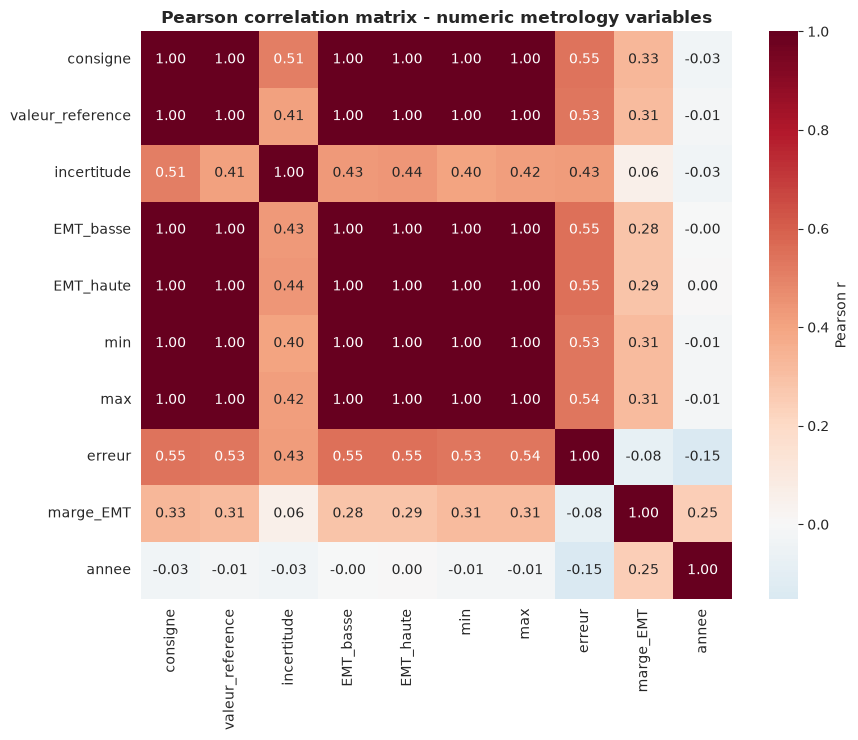

Strongest absolute correlations:


,var1,var2,pearson_r
13,valeur_reference,max,0.999981
12,valeur_reference,min,0.999981
35,min,max,0.999925
0,consigne,valeur_reference,0.999921
5,consigne,max,0.999919
4,consigne,min,0.999889
24,EMT_basse,EMT_haute,0.999620
2,consigne,EMT_basse,0.999445


In [7]:

corr_cols = ["consigne", "valeur_reference", "incertitude", "EMT_basse", "EMT_haute", "min", "max", "erreur", "marge_EMT", "annee"]
corr_cols = [c for c in corr_cols if c in df.columns]
corr_matrix = df[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "Pearson r"})
ax.set_title("Pearson correlation matrix - numeric metrology variables", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "03_correlation_heatmap.png", dpi=150)
plt.show()

strong_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack().reset_index()
)
strong_pairs.columns = ["var1", "var2", "pearson_r"]
strong_pairs = strong_pairs.reindex(strong_pairs["pearson_r"].abs().sort_values(ascending=False).index)
print("Strongest absolute correlations:")
display(strong_pairs.head(8))


### 4.4 Scatter plot - `valeur_reference` vs `consigne`

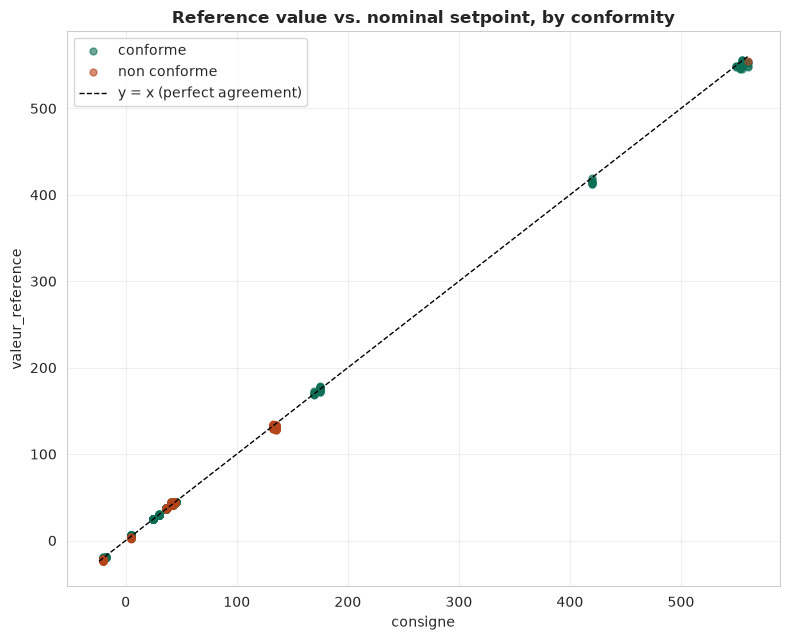

In [8]:

fig, ax = plt.subplots(figsize=(8, 6.5))
plot_df = df.dropna(subset=["valeur_reference", "consigne", "conforme"])
for verdict, color in [("conforme", "#0F6E56"), ("non conforme", "#B5451B")]:
    sub = plot_df[plot_df["conforme"] == verdict]
    ax.scatter(sub["consigne"], sub["valeur_reference"], s=25, alpha=0.6, color=color, label=verdict)
lims = [plot_df[["consigne", "valeur_reference"]].min().min(), plot_df[["consigne", "valeur_reference"]].max().max()]
ax.plot(lims, lims, "k--", linewidth=1, label="y = x (perfect agreement)")
ax.set_title("Reference value vs. nominal setpoint, by conformity", fontsize=12, fontweight="bold")
ax.set_xlabel("consigne"); ax.set_ylabel("valeur_reference"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "04_scatter_reference_vs_consigne.png", dpi=150)
plt.show()


### 4.5 Distribution by instrument, laboratory, EMT margin and outlier flag

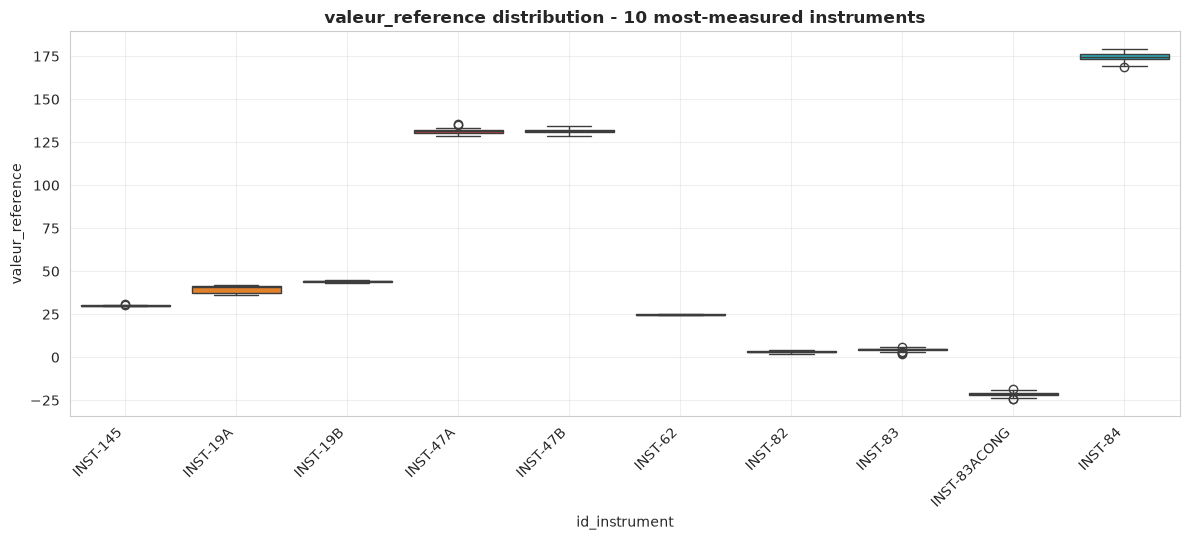

In [9]:

top_instruments = df["id_instrument"].value_counts().head(10).index
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=df[df["id_instrument"].isin(top_instruments)], x="id_instrument", y="valeur_reference",
            hue="id_instrument", ax=ax, legend=False)
ax.set_title("valeur_reference distribution - 10 most-measured instruments", fontsize=12, fontweight="bold")
ax.set_xlabel("id_instrument"); ax.set_ylabel("valeur_reference"); ax.grid(alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "05_distribution_by_instrument.png", dpi=150)
plt.show()


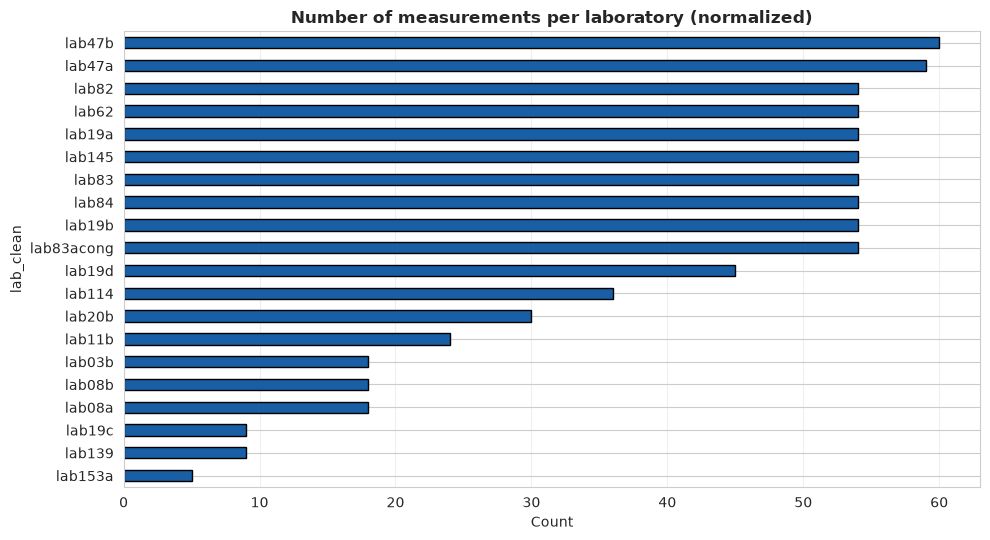

In [10]:

fig, ax = plt.subplots(figsize=(10, 5.5))
df["lab_clean"].value_counts().sort_values().plot(kind="barh", ax=ax, color="#185FA5", edgecolor="black")
ax.set_title("Number of measurements per laboratory (normalized)", fontsize=12, fontweight="bold")
ax.set_xlabel("Count"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "06_distribution_by_lab.png", dpi=150)
plt.show()


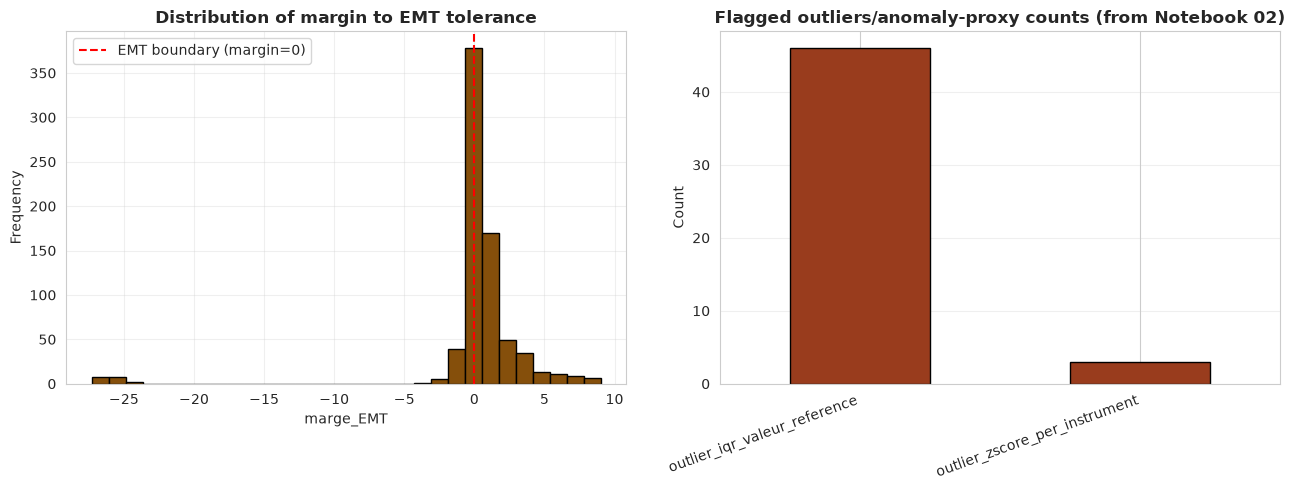

Rows with negative EMT margin (i.e. measurement interval breaches tolerance): 157 (21.4% of rows with a computable margin).


In [11]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df["marge_EMT"].dropna().hist(bins=30, ax=axes[0], color="#854F0B", edgecolor="black")
axes[0].axvline(0, color="red", linestyle="--", label="EMT boundary (margin=0)")
axes[0].set_title("Distribution of margin to EMT tolerance", fontsize=12, fontweight="bold")
axes[0].set_xlabel("marge_EMT"); axes[0].set_ylabel("Frequency"); axes[0].legend(); axes[0].grid(alpha=0.3)

outlier_counts = df[["outlier_iqr_valeur_reference", "outlier_zscore_per_instrument"]].sum()
outlier_counts.plot(kind="bar", ax=axes[1], color="#993C1D", edgecolor="black")
axes[1].set_title("Flagged outliers/anomaly-proxy counts (from Notebook 02)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Count"); axes[1].grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "07_emt_margin_and_outliers.png", dpi=150)
plt.show()

n_negative_margin = int((df["marge_EMT"] < 0).sum())
print(f"Rows with negative EMT margin (i.e. measurement interval breaches tolerance): {n_negative_margin} "
      f"({n_negative_margin/df['marge_EMT'].notna().sum()*100:.1f}% of rows with a computable margin).")


## 5. Statistical Analysis

### 5.1 Normality tests (Shapiro-Wilk, Kolmogorov-Smirnov, Anderson-Darling)

In [12]:

def normality_battery(series, name):
    data = series.dropna().values
    results = {"variable": name, "n": len(data)}
    if len(data) >= 3:
        sample = data if len(data) <= 5000 else np.random.choice(data, 5000, replace=False)
        shapiro_stat, shapiro_p = stats.shapiro(sample)
        results["shapiro_stat"] = round(shapiro_stat, 4)
        results["shapiro_p"] = round(shapiro_p, 4)
        results["shapiro_normal_at_5pct"] = shapiro_p > ALPHA

        ks_stat, ks_p = stats.kstest(data, stats.norm(loc=data.mean(), scale=data.std(ddof=1)).cdf)  # bug fix: scipy 1.18.0 kstest(..., args=(loc,scale)) raises TypeError internally; passing a bound .cdf callable is the working equivalent
        results["ks_stat"] = round(ks_stat, 4)
        results["ks_p"] = round(ks_p, 4)
        results["ks_normal_at_5pct"] = ks_p > ALPHA

        anderson_res = stats.anderson(data, dist="norm")
        crit_5pct = anderson_res.critical_values[2]  # index 2 corresponds to 5% significance level
        results["anderson_stat"] = round(anderson_res.statistic, 4)
        results["anderson_critical_5pct"] = round(crit_5pct, 4)
        results["anderson_normal_at_5pct"] = anderson_res.statistic < crit_5pct
    return results

normality_results = pd.DataFrame([normality_battery(df[c], c) for c in ["valeur_reference", "erreur", "incertitude", "marge_EMT"]])
display(normality_results)

for _, row in normality_results.iterrows():
    votes = [row.get("shapiro_normal_at_5pct"), row.get("ks_normal_at_5pct"), row.get("anderson_normal_at_5pct")]
    votes = [v for v in votes if v is not None]
    conclusion = "approximately normal" if sum(votes) >= 2 else "NOT normal"
    print(f"{row['variable']}: {sum(votes)}/{len(votes)} tests support normality at alpha={ALPHA} -> {conclusion}")


/tmp/ipykernel_671/564404189.py:16: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  anderson_res = stats.anderson(data, dist="norm")


,variable,n,shapiro_stat,shapiro_p,shapiro_normal_at_5pct,ks_stat,ks_p,ks_normal_at_5pct,anderson_stat,anderson_critical_5pct,anderson_normal_at_5pct
0,valeur_reference,763,0.6270,0.0,False,0.2951,0.0,False,88.6059,0.751,False
1,erreur,500,0.8706,0.0,False,0.1674,0.0,False,23.4440,0.751,False
2,incertitude,763,0.7025,0.0,False,0.2313,0.0,False,77.2929,0.751,False
3,marge_EMT,734,0.4243,0.0,False,0.3369,0.0,False,132.7275,0.751,False


valeur_reference: 0/3 tests support normality at alpha=0.05 -> NOT normal
erreur: 0/3 tests support normality at alpha=0.05 -> NOT normal
incertitude: 0/3 tests support normality at alpha=0.05 -> NOT normal
marge_EMT: 0/3 tests support normality at alpha=0.05 -> NOT normal


### 5.2 Correlation - Pearson, Spearman, Kendall

In [13]:

pearson = df[corr_cols].corr(method="pearson")
spearman = df[corr_cols].corr(method="spearman")
kendall = df[corr_cols].corr(method="kendall")

print("Pearson (linear) correlation - valeur_reference vs consigne:", round(pearson.loc["valeur_reference", "consigne"], 4))
print("Spearman (rank/monotonic) correlation - valeur_reference vs consigne:", round(spearman.loc["valeur_reference", "consigne"], 4))
print("Kendall (concordance) correlation - valeur_reference vs consigne:", round(kendall.loc["valeur_reference", "consigne"], 4))
print("\nIf Spearman/Kendall are notably higher than Pearson, the relationship is monotonic but not strictly linear.")


Pearson (linear) correlation - valeur_reference vs consigne: 0.9999
Spearman (rank/monotonic) correlation - valeur_reference vs consigne: 0.991
Kendall (concordance) correlation - valeur_reference vs consigne: 0.9345

If Spearman/Kendall are notably higher than Pearson, the relationship is monotonic but not strictly linear.


### 5.3 ANOVA - does mean error differ across laboratories?

In [14]:

groups = [g["erreur"].dropna().values for _, g in df.groupby("lab_clean") if g["erreur"].notna().sum() >= 5]
group_labels = [name for name, g in df.groupby("lab_clean") if g["erreur"].notna().sum() >= 5]

if len(groups) >= 2:
    f_stat, p_value = stats.f_oneway(*groups)
    print(f"One-way ANOVA on 'erreur' across {len(groups)} laboratories (n>=5 each):")
    print(f"  F-statistic = {f_stat:.4f}, p-value = {p_value:.4g}")
    if p_value < ALPHA:
        print(f"  -> p < {ALPHA}: mean error DIFFERS significantly across laboratories.")
    else:
        print(f"  -> p >= {ALPHA}: no significant evidence that mean error differs across laboratories.")
else:
    print("Not enough laboratories with >=5 non-missing 'erreur' values to run ANOVA.")


One-way ANOVA on 'erreur' across 17 laboratories (n>=5 each):
  F-statistic = 39.5929, p-value = 2.7e-77
  -> p < 0.05: mean error DIFFERS significantly across laboratories.


### 5.4 Chi-square - association between laboratory and conformity

In [15]:

contingency = pd.crosstab(df["lab_clean"], df["conforme"])
display(contingency)

if contingency.shape[0] >= 2 and contingency.shape[1] >= 2 and contingency.values.min() >= 0:
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
    print(f"\nChi-square test of independence: chi2={chi2:.4f}, dof={dof}, p-value={p_value:.4g}")
    if p_value < ALPHA:
        print(f"-> p < {ALPHA}: conformity status is significantly ASSOCIATED with laboratory.")
    else:
        print(f"-> p >= {ALPHA}: no significant evidence of association between laboratory and conformity.")
else:
    print("Contingency table not suitable for chi-square (need >=2 categories on both axes).")


conforme,conforme,non conforme
lab_clean,,
lab03b,13,5
lab08a,18,0
lab08b,17,1
lab114,36,0
lab139,9,0
lab145,54,0
lab19a,42,12
lab19b,26,28
lab19c,4,5



Chi-square test of independence: chi2=157.1619, dof=17, p-value=9.624e-25
-> p < 0.05: conformity status is significantly ASSOCIATED with laboratory.


### 5.5 Confidence intervals for mean error

In [16]:

def mean_ci(data, confidence=0.95):
    data = np.asarray(data)
    n = len(data)
    mean = data.mean()
    se = stats.sem(data)
    h = se * stats.t.ppf((1 + confidence) / 2, n - 1)
    return mean, mean - h, mean + h

overall = df["erreur"].dropna()
mean, lo, hi = mean_ci(overall)
print(f"Overall mean 'erreur' = {mean:.4f}  [95% CI: {lo:.4f}, {hi:.4f}]  (n={len(overall)})")

ci_rows = []
for instr, g in df.groupby("id_instrument"):
    vals = g["erreur"].dropna()
    if len(vals) >= 5:
        m, l, h = mean_ci(vals)
        ci_rows.append({"id_instrument": instr, "n": len(vals), "mean_erreur": round(m, 4),
                         "ci_lower": round(l, 4), "ci_upper": round(h, 4)})
ci_df = pd.DataFrame(ci_rows).sort_values("mean_erreur", ascending=False)
display(ci_df)


Overall mean 'erreur' = 1.0491  [95% CI: 0.8570, 1.2411]  (n=500)


,id_instrument,n,mean_erreur,ci_lower,ci_upper
0,INST-08A,18,6.0172,4.6374,7.3971
4,INST-139,9,5.2444,3.4266,7.0623
1,INST-08B,18,3.2622,1.8136,4.7109
12,INST-47A,39,2.7897,2.2272,3.3523
13,INST-47B,40,2.6475,1.7992,3.4958
16,INST-83ACONG,54,1.7481,1.4594,2.0368
15,INST-83,18,0.9311,0.3209,1.5413
6,INST-153A,5,0.6600,0.5489,0.7711
7,INST-19A,36,0.5694,0.3962,0.7427
14,INST-62,36,0.2417,0.1438,0.3395


## 6. Time-Series Analysis

In [17]:

has_temporal_info = "annee" in df.columns and df["annee"].notna().sum() > 0
print(f"Dataset contains temporal information: {has_temporal_info} "
      f"(campaign years observed: {sorted(df['annee'].dropna().unique())})")


Dataset contains temporal information: True (campaign years observed: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)])


### 6.1 Trend analysis - mean error by campaign year

,annee,mean,std,count
0,2020,3.250000,3.483377,24
1,2021,2.210833,1.448339,24
2,2022,0.427304,1.810484,115
3,2023,1.272072,2.314742,111
4,2024,1.234545,2.298800,110
5,2025,0.580431,1.588128,116


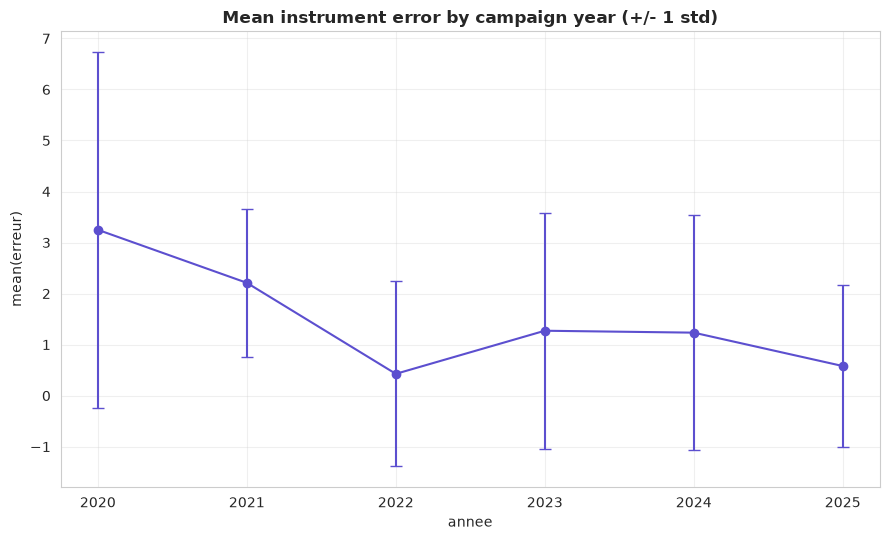

Linear trend of yearly mean error: slope=-0.44091/year, r=-0.773, p=0.07115
-> No statistically significant linear trend at alpha=0.05 (only 6 yearly points - limited statistical power).


In [18]:

yearly = df.groupby("annee")["erreur"].agg(["mean", "std", "count"]).reset_index()
display(yearly)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(yearly["annee"], yearly["mean"], yerr=yearly["std"], marker="o", capsize=4, color="#5C4FCF")
ax.set_title("Mean instrument error by campaign year (+/- 1 std)", fontsize=12, fontweight="bold")
ax.set_xlabel("annee"); ax.set_ylabel("mean(erreur)"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "08_trend_by_year.png", dpi=150)
plt.show()

if len(yearly) >= 3:
    slope, intercept, r, p, se = stats.linregress(yearly["annee"], yearly["mean"])
    print(f"Linear trend of yearly mean error: slope={slope:.5f}/year, r={r:.3f}, p={p:.4g}")
    print("-> " + ("Statistically significant trend" if p < ALPHA else "No statistically significant linear trend")
          + f" at alpha={ALPHA} (only {len(yearly)} yearly points - limited statistical power).")
else:
    print("Fewer than 3 yearly points available - trend test skipped as statistically meaningless.")


### 6.2 Per-instrument time series with rolling statistics

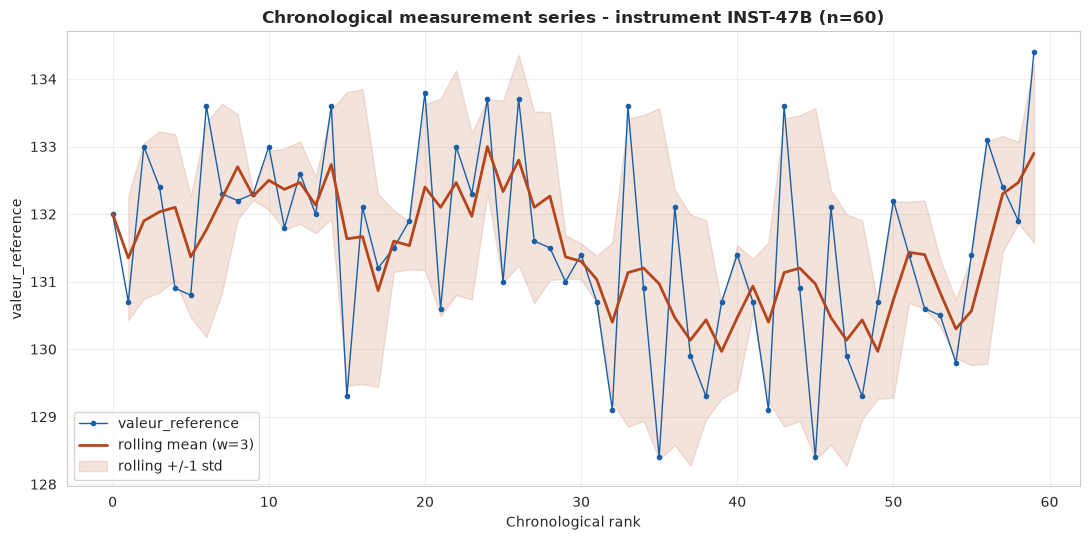

Instrument analyzed: INST-47B - 60 chronological measurements available.


In [19]:

most_measured = df["id_instrument"].value_counts().idxmax()
series_df = df[df["id_instrument"] == most_measured].sort_values("chrono_rank_in_instrument")
s = series_df.set_index("chrono_rank_in_instrument")["valeur_reference"]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(s.index, s.values, marker="o", markersize=3, linewidth=1, color="#185FA5", label="valeur_reference")
ax.plot(s.index, s.rolling(3, min_periods=1).mean(), color="#B5451B", linewidth=2, label="rolling mean (w=3)")
roll_mean = s.rolling(3, min_periods=1).mean()
roll_std = s.rolling(3, min_periods=1).std()
ax.fill_between(s.index, roll_mean - roll_std, roll_mean + roll_std,
                 color="#B5451B", alpha=0.15, label="rolling +/-1 std")
ax.set_title(f"Chronological measurement series - instrument {most_measured} (n={len(s)})", fontsize=12, fontweight="bold")
ax.set_xlabel("Chronological rank"); ax.set_ylabel("valeur_reference"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "09_instrument_series_rolling.png", dpi=150)
plt.show()
print(f"Instrument analyzed: {most_measured} - {len(s)} chronological measurements available.")


### 6.3 Autocorrelation and partial autocorrelation

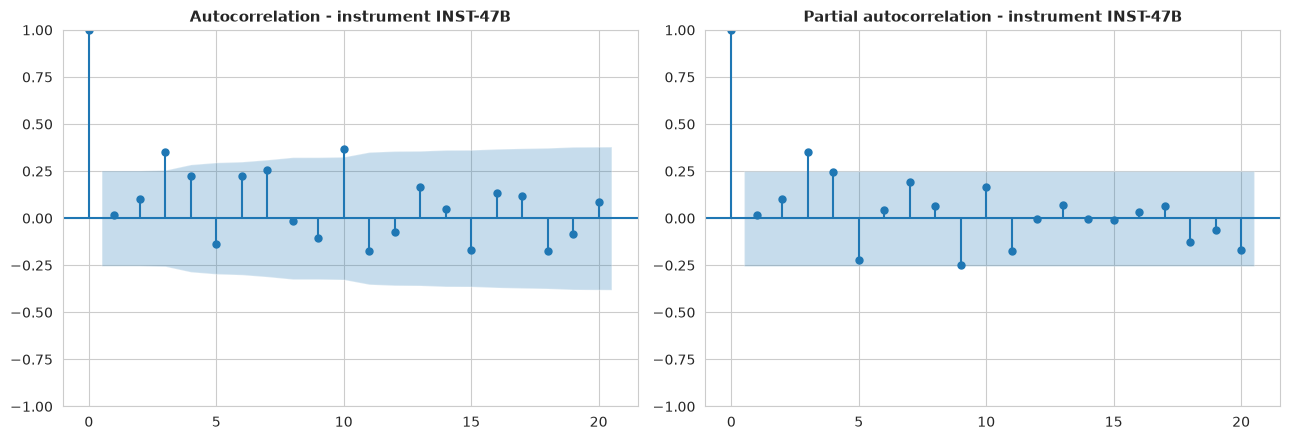

In [20]:

MIN_LAGS_REQUIRED = 10
if len(s.dropna()) >= MIN_LAGS_REQUIRED:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    plot_acf(s.dropna(), ax=axes[0], lags=min(20, len(s)//2 - 1))
    axes[0].set_title(f"Autocorrelation - instrument {most_measured}", fontsize=11, fontweight="bold")
    plot_pacf(s.dropna(), ax=axes[1], lags=min(20, len(s)//2 - 1), method="ywm")
    axes[1].set_title(f"Partial autocorrelation - instrument {most_measured}", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.savefig(REPORTS_FIGURES / "10_acf_pacf.png", dpi=150)
    plt.show()
else:
    print(f"Series has only {len(s.dropna())} points (< {MIN_LAGS_REQUIRED}) - ACF/PACF would be statistically "
          f"unreliable and are skipped rather than shown with misleading confidence bands.")


### 6.4 Stationarity tests (ADF, KPSS)

In [21]:

def stationarity_report(series, name):
    data = series.dropna().values
    if len(data) < 8:
        print(f"{name}: only {len(data)} points - stationarity tests skipped (statistically unreliable below ~8 points).")
        return
    adf_stat, adf_p, *_ = adfuller(data, autolag="AIC")
    print(f"[{name}] ADF test: statistic={adf_stat:.4f}, p-value={adf_p:.4g} -> "
          f"{'stationary' if adf_p < ALPHA else 'NOT stationary'} at alpha={ALPHA}")
    try:
        kpss_stat, kpss_p, *_ = kpss(data, regression="c", nlags="auto")
        print(f"[{name}] KPSS test: statistic={kpss_stat:.4f}, p-value={kpss_p:.4g} -> "
              f"{'NOT stationary' if kpss_p < ALPHA else 'stationary'} at alpha={ALPHA}")
    except Exception as e:
        print(f"[{name}] KPSS test could not be computed: {e}")

stationarity_report(yearly["mean"], "yearly mean error (aggregate)")
stationarity_report(s, f"instrument {most_measured} chronological series")


yearly mean error (aggregate): only 6 points - stationarity tests skipped (statistically unreliable below ~8 points).
[instrument INST-47B chronological series] ADF test: statistic=-1.8143, p-value=0.3734 -> NOT stationary at alpha=0.05
[instrument INST-47B chronological series] KPSS test: statistic=0.5692, p-value=0.02607 -> NOT stationary at alpha=0.05


### 6.5 Change-point detection

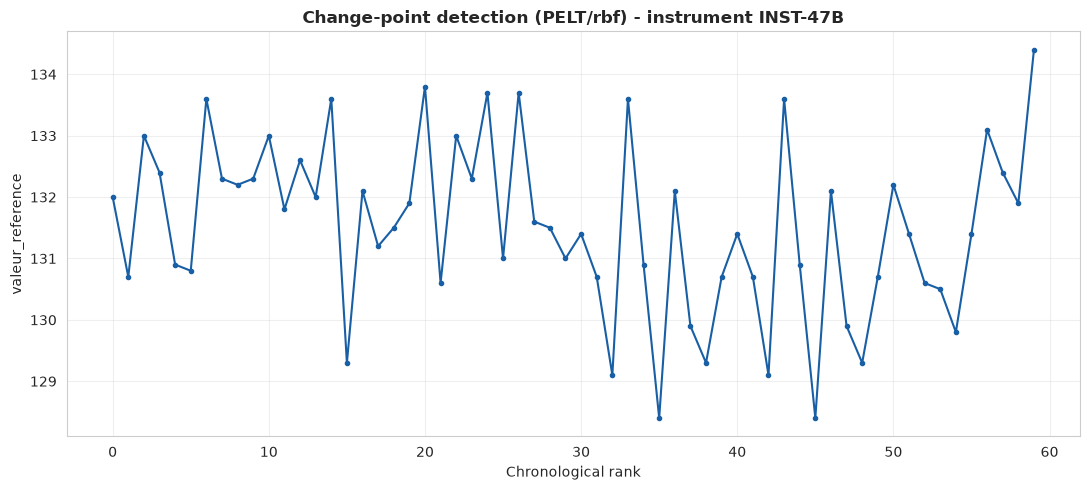

Detected change point(s) at chronological rank(s): none


In [22]:

change_points = []
if len(s.dropna()) >= 10:
    signal = s.dropna().values.reshape(-1, 1)
    algo = rpt.Pelt(model="rbf").fit(signal)
    penalty = 3 * np.log(len(signal))
    change_points = algo.predict(pen=penalty)
    change_points_interior = [c for c in change_points if c < len(signal)]

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(range(len(signal)), signal, color="#185FA5", marker="o", markersize=3)
    for cp in change_points_interior:
        ax.axvline(cp, color="red", linestyle="--", alpha=0.7)
    ax.set_title(f"Change-point detection (PELT/rbf) - instrument {most_measured}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Chronological rank"); ax.set_ylabel("valeur_reference"); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(REPORTS_FIGURES / "11_changepoint_detection.png", dpi=150)
    plt.show()
    print(f"Detected change point(s) at chronological rank(s): {change_points_interior if change_points_interior else 'none'}")
else:
    change_points_interior = []
    print(f"Series too short ({len(s.dropna())} points) for reliable change-point detection - skipped.")


### 6.6 Instrument aging, calibration/verification interval analysis

,id_instrument,n_measurements,first_year,last_year,first_value,last_value,age_years,net_change
5,INST-11B,24,2020,2025,1003.00,100.40,5,-902.60
6,INST-139,9,2023,2025,412.00,419.00,2,7.00
20,INST-83ACONG,54,2020,2025,-24.00,-19.20,5,4.80
4,INST-114,36,2022,2025,2.90,6.40,3,3.50
9,INST-19A,54,2020,2025,37.70,41.10,5,3.40
16,INST-47B,60,2020,2025,132.00,134.40,5,2.40
3,INST-08B,18,2020,2025,552.60,554.99,5,2.39
15,INST-47A,59,2020,2025,131.00,129.20,5,-1.80
19,INST-83,54,2020,2025,3.40,4.90,5,1.50
11,INST-19C,9,2021,2021,41.58,40.22,0,-1.36


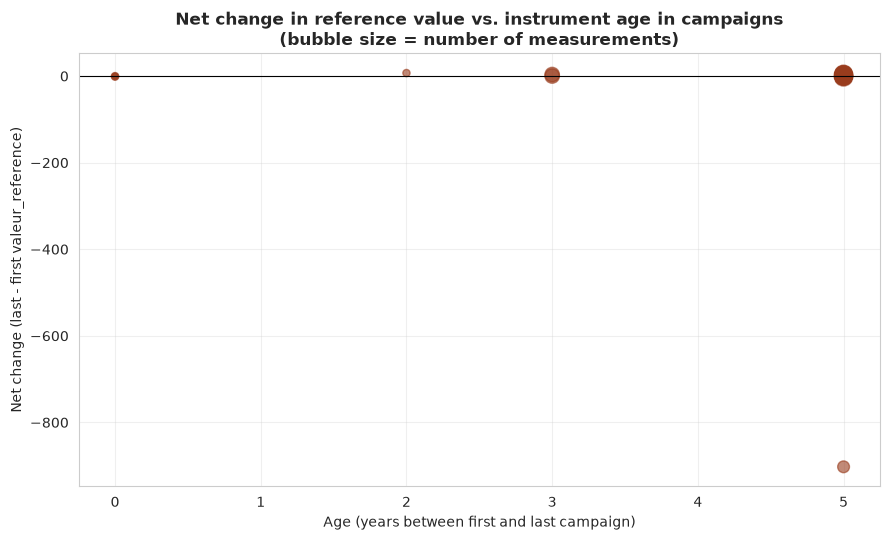

In [23]:

aging = (
    df.groupby("id_instrument")
      .agg(n_measurements=("valeur_reference", "count"),
           first_year=("annee", "min"), last_year=("annee", "max"),
           first_value=("valeur_reference", "first"), last_value=("valeur_reference", "last"))
      .reset_index()
)
aging["age_years"] = aging["last_year"] - aging["first_year"]
aging["net_change"] = aging["last_value"] - aging["first_value"]
display(aging.sort_values("net_change", key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(aging["age_years"], aging["net_change"], s=aging["n_measurements"] * 3, alpha=0.6, color="#993C1D")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Net change in reference value vs. instrument age in campaigns\n(bubble size = number of measurements)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Age (years between first and last campaign)")
ax.set_ylabel("Net change (last - first valeur_reference)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "12_instrument_aging.png", dpi=150)
plt.show()


In [24]:

gaps = (
    df.dropna(subset=["annee"])
      .drop_duplicates(subset=["id_instrument", "annee"])
      .sort_values(["id_instrument", "annee"])
      .groupby("id_instrument")["annee"].apply(lambda s: s.diff().dropna().tolist())
)
all_gaps = [g for sub in gaps for g in sub]
if all_gaps:
    gaps_series = pd.Series(all_gaps)
    print("Distribution of gaps (in years) between consecutive campaigns, per instrument:")
    display(gaps_series.value_counts().sort_index().to_frame("count"))
    print(f"\n{(gaps_series == 1).mean()*100:.1f}% of consecutive campaigns are exactly 1 year apart "
          f"(the expected annual calibration/verification interval).")
else:
    gaps_series = pd.Series(dtype=float)
    print("Not enough multi-year instruments to analyze calibration interval gaps.")


Distribution of gaps (in years) between consecutive campaigns, per instrument:


,count
1.0,88



100.0% of consecutive campaigns are exactly 1 year apart (the expected annual calibration/verification interval).


## 7. Conclusions

In [25]:

print("EDA / STATISTICAL / TIME-SERIES ANALYSIS - KEY FINDINGS (data-driven)")
print("=" * 75)
print(f"- {len(df)} cleaned measurements across {df['id_instrument'].nunique()} instruments and "
      f"{df['lab_clean'].nunique()} laboratories, spanning {df['annee'].min()}-{df['annee'].max()}.")
print(f"- Normality: {(normality_results['shapiro_normal_at_5pct']==True).sum()} / {len(normality_results)} "
      f"key variables pass the Shapiro-Wilk normality test at alpha={ALPHA} "
      f"- parametric tests above should be read with this in mind.")
print(f"- {n_negative_margin} measurement(s) have a negative EMT margin (tolerance breach) out of "
      f"{df['marge_EMT'].notna().sum()} computable rows.")
print(f"- Most-measured instrument ({most_measured}, n={len(s)}) shows "
      f"{'a detected change point' if change_points_interior else 'no strong change point'} "
      f"in its chronological series.")
if len(all_gaps):
    print(f"- {(gaps_series==1).mean()*100:.1f}% of campaign gaps are exactly 1 year, confirming an overall annual cadence "
          f"with some exceptions worth investigating operationally.")
else:
    print("- Insufficient multi-year data to characterize the calibration cadence.")
logger.info("Notebook 03 completed successfully.")


EDA / STATISTICAL / TIME-SERIES ANALYSIS - KEY FINDINGS (data-driven)
- 763 cleaned measurements across 22 instruments and 20 laboratories, spanning 2020-2025.
- Normality: 0 / 4 key variables pass the Shapiro-Wilk normality test at alpha=0.05 - parametric tests above should be read with this in mind.
- 157 measurement(s) have a negative EMT margin (tolerance breach) out of 734 computable rows.
- Most-measured instrument (INST-47B, n=60) shows no strong change point in its chronological series.
- 100.0% of campaign gaps are exactly 1 year, confirming an overall annual cadence with some exceptions worth investigating operationally.
2026-08-22 12:52:03,952 | INFO | Notebook 03 completed successfully.


---
**End of Notebook 03.** Next: Notebook 04 - Feature Engineering & Feature Selection.
